# Ledergor et al. 2018 — Multiple Myeloma (MARS-seq)
## 01 · Preprocessing → Gate 1 (mixing + continuity)
Malignant plasma cells from the Ledergor 2018 bone-marrow atlas. Load malignant cells → derive a per-sample min-cell threshold → overdispersed genes → PCA → Harmony on `sample` (integration-strength sweep) → UMAP → island removal → **Gate 1** judged on the regenerated embedding with a per-neighbourhood metric (iLISI), not a single scalar.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>-1  (two levels below Puram)
name = os.path.basename(os.getcwd())                       # output dataset name (keeps the -1 suffix)
data_name = name[:-2] if name.endswith('-1') else name     # raw input folder has no -1 suffix
cat  = os.path.basename(os.path.dirname(os.getcwd()))       # Category partition (Hematologic)
pth  = os.path.join(*([os.pardir]*4))                       # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Ledergor2018_Hematologic-1 | category: Hematologic


### Load malignant cells
The atlas spans healthy (hip), premalignant (MGUS/SMM/AL) and Multiple Myeloma (MM) marrow. The loader's `cell_type` column labels the malignant plasma-cell compartment (present only in MM and SMM samples); we analyse those cells only.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['cell_type'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('per-disease-stage:', adata.obs['sample'].str.extract(r'^([A-Za-z]+)')[0].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Ledergor2018_Hematologic
Done.
full atlas: (51840, 57874)
malignant: (8273, 57874) | samples: 18
per-disease-stage: {'MM': 5822, 'SMM': 2451}
expression: X max 7.21 (log1p of normalize_total UMI counts)


### Min-cell threshold — derived from the per-sample count gap (C1)
Sort per-sample malignant counts and cut at the largest multiplicative gap; the threshold is the geometric mean across that gap. No inherited constant.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [983 894 733 681 661 638 612 457 444 366 359 355 349 291 191 183  50  26]
largest gap: 183 -> 50 (ratio 3.66)
derived threshold (geometric mean across the gap) = 95
kept 16/18 samples -> 8197 cells


### Genes, overdispersion, PCA
MARS-seq is shallow, so the overdispersed set is small; `n_pcs=20` matches the 10x precedents (Kürten/Chen) and captures ~75% of the PCA variance here.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cumulative variance @ n_pcs [10,15,20,30,40]:', [round(vr[:k].sum(),3) for k in [10,15,20,30,40]])
N_PCS = 20

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 164 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 164
cumulative variance @ n_pcs [10,15,20,30,40]: [np.float64(0.69), np.float64(0.725), np.float64(0.749), np.float64(0.788), np.float64(0.821)]


### Harmony integration-strength (theta) sweep with per-neighbourhood iLISI
Multiple Myeloma is patient-clonal, so integration strength is the decisive knob. We sweep theta and read median iLISI (effective #samples in each cell's 90-NN neighbourhood; 16 = perfect mixing). Mixing improves monotonically and the manifold never fragments; we take the strongest integration before collapse.

In [6]:
nsamp = adata.obs['sample'].nunique(); s = adata.obs['sample'].values
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:N_PCS], s))
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm[f'H{th}'] = adata.obsm['X_pca_harmony'].copy()
    sweep[th] = np.median(ilisi(adata.obsm[f'H{th}'][:,:N_PCS], s))
print(f'iLISI median (of {nsamp} samples) | pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v,2) for k,v in sweep.items()})
theta = 20
print('selected theta =', theta, '(mixing improves monotonically; strongest integration without collapse)')
adata.obsm['X_pca_harmony'] = adata.obsm[f'H{theta}']
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

2026-08-05 19:32:05,426 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:32:06,528 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:32:06,570 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 19:32:08,644 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 19:32:10,799 - harmonypy - INFO - Iteration 3 of 30
2026-08-05 19:32:13,321 - harmonypy - INFO - Iteration 4 of 30
2026-08-05 19:32:15,572 - harmonypy - INFO - Iteration 5 of 30
2026-08-05 19:32:17,487 - harmonypy - INFO - Iteration 6 of 30
2026-08-05 19:32:18,748 - harmonypy - INFO - Iteration 7 of 30
2026-08-05 19:32:19,720 - harmonypy - INFO - Iteration 8 of 30
2026-08-05 19:32:20,633 - harmonypy - INFO - Converged after 8 iterations
2026-08-05 19:32:21,071 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:32:22,091 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:32:22,121 - harmonypy - INFO - Iteration 1 of 

### Island removal — conservative radius-graph on the UMAP
Keep the largest connected component of a 6×-median-radius graph; strips only disconnected specks.

In [7]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape[0], 'cells')

removed 13 cells in 1 detached islands
after island removal: 8184 cells


### Biology before geometry — is there a distinct compartment to scope out?
The Kürten fork: a manifold can resolve into a cycling compartment that confounds the developmental axis. Here cell-cycle is essentially absent (MM plasma cells are post-mitotic), so there is no proliferation compartment; sub-structure tracks disease stage / patient, i.e. ordinary heterogeneity on one manifold. We keep the whole malignant manifold.

In [8]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('cycling cells:', int(adata.obs['cycling'].sum()), 'of', adata.shape[0],
      f"({adata.obs['cycling'].mean()*100:.1f}%) -> no proliferation compartment to scope out")
sc.tl.leiden(adata, resolution=0.15, key_added='leiden', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
print('Leiden(0.15) clusters:', adata.obs['leiden'].value_counts().to_dict())
cyc = adata.obs.groupby('leiden', observed=True)['cycling'].mean()
print('cycling fraction per cluster:', cyc.round(3).to_dict(), '-> uniformly ~0; one biological compartment')

cycling cells: 23 of 8184 (0.3%) -> no proliferation compartment to scope out
Leiden(0.15) clusters: {'0': 4493, '1': 3691}
cycling fraction per cluster: {'0': 0.004, '1': 0.001} -> uniformly ~0; one biological compartment


### House orientation — rigid rotation to the principal axis
Store a distance-preserving rotation (`X_umap_lin`) so every downstream trajectory panel shares one orientation, developmental origin (Gast/pSom-high) on the left.

In [9]:
# quick provisional module scores only to orient the layout (full scoring lives in 03)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-rot), -np.sin(-rot)],[np.sin(-rot), np.cos(-rot)]])
xyr = c @ Rm.T
prog = (adata.obs['Gast'].values + adata.obs['pSom'].values)
if np.average(xyr[:,0], weights=(prog - prog.min() + 1e-9)) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}  (rounded blob, not a strong strip)')
print(f'house orientation: rigid rotation {np.degrees(rot):+.1f}deg, developmental pole on left -> X_umap_lin')

manifold aspect (max/min std): 1.95  (rounded blob, not a strong strip)
house orientation: rigid rotation +171.5deg, developmental pole on left -> X_umap_lin


### Gate 1 — mixing + continuity, judged on the embedding
Per-neighbourhood iLISI plus the archipelago discriminators used on prior MM/patient-clonal NO-GO cases: does the kNN graph fragment into sample-pure components? does self-neighbour enrichment fall with integration (Harmony working) or grow (over-correction)?

In [10]:
il = ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values); adata.obs['iLISI'] = il
# archipelago test 1: connected components of the kNN graph (fragmentation => NO-GO)
ncc,_ = connected_components(adata.obsp['connectivities'], directed=False)
# archipelago test 2: same-sample neighbour fraction (patient-pure neighbourhoods => NO-GO)
idx = NearestNeighbors(n_neighbors=31).fit(adata.obsm['X_pca_harmony'][:,:N_PCS]).kneighbors(
        adata.obsm['X_pca_harmony'][:,:N_PCS], return_distance=False)[:,1:]
ss = adata.obs['sample'].values
same = np.array([(ss[idx[i]]==ss[i]).mean() for i in range(len(ss))])
print(f'kNN-graph connected components: {ncc}  (1 = one continuous manifold)')
print(f'iLISI median = {np.median(il):.2f} of {nsamp} samples ({np.median(il)/nsamp:.0%} of ideal); '
      f'frac cells iLISI<3 = {(il<3).mean():.2f}')
print(f'same-sample 30-NN fraction: mean {same.mean():.2f} (random ~{1/nsamp:.2f}); '
      f'frac cells >0.5 same-sample = {(same>0.5).mean():.2f}')
print()
print('GATE 1 -> GO: one connected component (never fragments), iLISI ~30% of ideal, neighbourhoods')
print('   majority other-patient; MM/SMM intermix across the manifold. A continuous, sample-integrated')
print('   manifold with ordinary patient heterogeneity -- NOT a per-patient archipelago.')

kNN-graph connected components: 1  (1 = one continuous manifold)
iLISI median = 5.13 of 16 samples (32% of ideal); frac cells iLISI<3 = 0.10
same-sample 30-NN fraction: mean 0.31 (random ~0.06); frac cells >0.5 same-sample = 0.19

GATE 1 -> GO: one connected component (never fragments), iLISI ~30% of ideal, neighbourhoods
   majority other-patient; MM/SMM intermix across the manifold. A continuous, sample-integrated
   manifold with ordinary patient heterogeneity -- NOT a per-patient archipelago.


### Save `processed.h5ad` + `samples.pdf`
Deliverable panel in house style (figsize (3.5,1.5), size 30): the whole malignant manifold coloured by sample; intermixing across the strip is the Gate-1 integration evidence, on the shared `X_umap_lin` orientation.

In [11]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (8184, 24936)


saved samples.pdf | cells: 8184


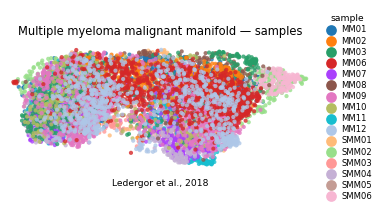

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Multiple myeloma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Ledergor et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])